In [1]:
# ==================================================
# FIRST: UPLOAD, LOAD AND PREPARE THE NINE CSV FILES
# ==================================================


from google.colab import files
from IPython.display import display


import io
import re
import json
import hashlib
import platform
import zipfile


from pathlib import Path


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt




# --------------------------------------------------
# 1. Upload the CSV files
# --------------------------------------------------


print("Upload the nine CSV files together.")
uploaded = files.upload()


EXPECTED_FILES = [
    "ride_requests.csv",
    "cab_zone_shift_history.csv",
    "cab_daily_history.csv",
    "daily_context.csv",
    "future_january_2026_plan.csv",
    "future_cash_calendar.csv",
    "scenario_assumptions.csv",
    "DATA_DICTIONARY.csv",
    "INSTRUCTOR_monthly_controls.csv"
]




# --------------------------------------------------
# 2. Match filenames safely
#
# Examples:
# cab_daily_history(1).csv -> cab_daily_history.csv
# cab_daily_history (2).csv -> cab_daily_history.csv
#
# This changes only the internal filename mapping.
# It does not change the data.
# --------------------------------------------------


def normalise_filename(filename):
    name = Path(filename).name.strip()


    name = re.sub(
        r"(?:\s*\(\d+\))+(?=\.csv$)",
        "",
        name,
        flags=re.IGNORECASE
    )


    return name.casefold()




source_map = {}


for expected in EXPECTED_FILES:


    matches = [
        actual
        for actual in uploaded
        if normalise_filename(actual)
        == normalise_filename(expected)
    ]


    if len(matches) == 0:
        raise ValueError(
            f"Missing required CSV: {expected}"
        )


    if len(matches) > 1:
        raise ValueError(
            f"Multiple files match {expected}: {matches}. "
            "Upload only one copy of each dataset."
        )


    source_map[expected] = matches[0]




# --------------------------------------------------
# 3. Output folder and helper functions
# --------------------------------------------------


OUTPUT_DIR = Path("fleet_class_results")
OUTPUT_DIR.mkdir(exist_ok=True)




def save_csv(frame, filename):
    frame.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )




def require(condition, message):
    if not bool(condition):
        raise ValueError(message)




def money_equal(a, b):
    return np.allclose(
        np.asarray(a, dtype=np.float64),
        np.asarray(b, dtype=np.float64),
        atol=0.01,
        rtol=0
    )




# --------------------------------------------------
# 4. Record versions and input-file hashes
# --------------------------------------------------


environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__
}


input_hashes = {
    canonical: hashlib.sha256(
        uploaded[actual]
    ).hexdigest()
    for canonical, actual in source_map.items()
}




# --------------------------------------------------
# 5. Load eight smaller files
#    Read the large request file in chunks
# --------------------------------------------------


tables = {}
inventory_rows = []
ride_sample = None
ride_status_counts = {}
ride_structural_missingness_ok = True


for canonical in EXPECTED_FILES:


    actual = source_map[canonical]
    file_bytes = uploaded[actual]


    if canonical == "ride_requests.csv":


        row_count = 0
        column_names = []


        for chunk in pd.read_csv(
            io.BytesIO(file_bytes),
            chunksize=100_000
        ):


            row_count += len(chunk)


            if ride_sample is None:
                ride_sample = chunk.head(10).copy()
                column_names = chunk.columns.tolist()


            for status, count in (
                chunk["status"].value_counts().items()
            ):
                ride_status_counts[status] = (
                    ride_status_counts.get(status, 0)
                    + int(count)
                )


            completed = chunk["status"].eq("completed")


            actual_trip_fields = [
                "actual_paid_km",
                "actual_empty_km",
                "actual_trip_min"
            ]


            completed_values_present = (
                chunk.loc[
                    completed,
                    actual_trip_fields
                ].notna().all().all()
            )


            unsuccessful_values_blank = (
                chunk.loc[
                    ~completed,
                    actual_trip_fields
                ].isna().all().all()
            )


            ride_structural_missingness_ok = (
                ride_structural_missingness_ok
                and completed_values_present
                and unsuccessful_values_blank
            )


        loading_method = "Read in chunks; preview retained"
        ride_row_count = row_count


    else:


        frame = pd.read_csv(
            io.BytesIO(file_bytes)
        )


        if "date" in frame.columns:
            frame["date"] = pd.to_datetime(
                frame["date"],
                errors="raise"
            )


        tables[canonical] = frame


        row_count = len(frame)
        column_names = frame.columns.tolist()
        loading_method = "Loaded as DataFrame"


    inventory_rows.append({
        "dataset": canonical,
        "uploaded_filename": actual,
        "rows": row_count,
        "columns": len(column_names),
        "loading_method": loading_method,
        "column_names": ", ".join(column_names)
    })


inventory = pd.DataFrame(inventory_rows)




# --------------------------------------------------
# 6. Create working copies
# --------------------------------------------------


daily = (
    tables["cab_daily_history.csv"]
    .sort_values("date", kind="stable")
    .reset_index(drop=True)
    .copy()
)


panel = (
    tables["cab_zone_shift_history.csv"]
    .sort_values(
        ["date", "zone", "shift"],
        kind="stable"
    )
    .reset_index(drop=True)
    .copy()
)


context = (
    tables["daily_context.csv"]
    .sort_values("date", kind="stable")
    .reset_index(drop=True)
    .copy()
)


future_plan = (
    tables["future_january_2026_plan.csv"]
    .sort_values(
        ["date", "zone", "shift"],
        kind="stable"
    )
    .reset_index(drop=True)
    .copy()
)


future_cash = (
    tables["future_cash_calendar.csv"]
    .sort_values("date", kind="stable")
    .reset_index(drop=True)
    .copy()
)


scenario_register = tables[
    "scenario_assumptions.csv"
].copy()


dictionary = tables[
    "DATA_DICTIONARY.csv"
].copy()


monthly_controls = tables[
    "INSTRUCTOR_monthly_controls.csv"
].copy()




# --------------------------------------------------
# 7. Freeze the mathematical settings
# --------------------------------------------------


N_SIMULATIONS = 10_000
SEED = 20261102
OPENING_CASH = 1_000_000.0


future_dates = pd.date_range(
    "2026-01-01",
    "2026-01-31",
    freq="D"
)


N_DAYS = len(future_dates)


SCENARIOS = {
    "baseline": 1.00,
    "fuel_plus_10pct": 1.10,
    "fuel_plus_20pct": 1.20
}


COST_COLUMNS = [
    "fuel_cost_inr",
    "distance_maintenance_inr",
    "processing_fees_inr",
    "driver_pay_inr",
    "repairs_inr"
]


OUTCOME_COLUMNS = [
    "completed_trips",
    "customer_cancellations",
    "driver_cancellations",
    "unfulfilled_requests"
]


COUNT_COLUMNS = [
    "requests",
    *OUTCOME_COLUMNS
]


MODEL_COLUMNS = [
    *COUNT_COLUMNS,
    "gross_fare_inr",
    "refunds_inr",
    "net_revenue_inr",
    "cash_sales_inr",
    "digital_sales_inr",
    *COST_COLUMNS,
    "available_vehicle_hours_actual",
    "used_vehicle_hours_actual"
]




# --------------------------------------------------
# 8. Save preparation records
# --------------------------------------------------


save_csv(inventory, "input_inventory.csv")


(OUTPUT_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2)
)


(OUTPUT_DIR / "input_file_hashes.json").write_text(
    json.dumps(input_hashes, indent=2)
)


print("\nAll nine CSV files have been read.")
print("Filename suffixes such as '(1)' were handled.")
print("Original uploaded bytes remain unchanged.")
print("Working copies and fixed settings are ready.")

Upload the nine CSV files together.


Saving ride_requests.csv to ride_requests.csv
Saving scenario_assumptions.csv to scenario_assumptions.csv
Saving INSTRUCTOR_monthly_controls.csv to INSTRUCTOR_monthly_controls.csv
Saving future_january_2026_plan.csv to future_january_2026_plan.csv
Saving future_cash_calendar.csv to future_cash_calendar.csv
Saving DATA_DICTIONARY.csv to DATA_DICTIONARY.csv
Saving daily_context.csv to daily_context.csv
Saving cab_zone_shift_history.csv to cab_zone_shift_history.csv
Saving cab_daily_history.csv to cab_daily_history.csv

All nine CSV files have been read.
Filename suffixes such as '(1)' were handled.
Original uploaded bytes remain unchanged.
Working copies and fixed settings are ready.


In [2]:
import sys
import numpy as np
import pandas as pd
import hashlib
import os

# 1. Record Python, NumPy, and pandas versions
print("=== ENVIRONMENT VERSIONS ===")
print(f"Python Version : {sys.version.split()[0]}")
print(f"NumPy Version  : {np.__version__}")
print(f"Pandas Version : {pd.__version__}")
print("=" * 50)

# Load Data Dictionary to lookup unique keys
df_dd = pd.read_csv('DATA_DICTIONARY.csv')

# List of all 9 files specified in the prompt
files_to_inspect = [
    'ride_requests.csv',
    'cab_zone_shift_history.csv',
    'cab_daily_history.csv',
    'daily_context.csv',
    'future_january_2026_plan.csv',
    'future_cash_calendar.csv',
    'scenario_assumptions.csv',
    'DATA_DICTIONARY.csv',
    'INSTRUCTOR_monthly_controls.csv'
]

file_to_df = {}

print("\n=== FILE INSPECTION & HASHES ===")
for fname in files_to_inspect:
    if not os.path.exists(fname):
        print(f"\n[WARNING] {fname} not found in the current directory.")
        continue

    # Compute SHA-256 hash of original uploaded bytes
    sha256_hash = hashlib.sha256()
    with open(fname, "rb") as f:
        for byte_block in iter(lambda: f.read(65536), b""):
            sha256_hash.update(byte_block)
    file_hash = sha256_hash.hexdigest()

    # Load DataFrame without modifying originals
    df = pd.read_csv(fname)
    var_name = fname.replace('.csv', '').replace('-', '_')
    file_to_df[fname] = df

    # Find unique key from data dictionary
    sub_dd = df_dd[df_dd['file'] == fname]
    unique_keys = sub_dd['unique_key'].dropna().unique().tolist() if 'unique_key' in sub_dd.columns else []

    print(f"File         : {fname}")
    print(f"DataFrame    : df_{var_name}")
    print(f"Row Count    : {len(df):,}")
    print(f"Column Count : {len(df.columns)}")
    print(f"Columns      : {list(df.columns)}")
    print(f"Unique Key   : {unique_keys if unique_keys else 'Not explicitly defined in DD'}")
    print(f"SHA-256 Hash : {file_hash}")
    print("-" * 50)

print("\nFilename-to-DataFrame mapping created successfully in `file_to_df` dictionary.")

=== ENVIRONMENT VERSIONS ===
Python Version : 3.13.18
NumPy Version  : 2.1.3
Pandas Version : 2.2.3

=== FILE INSPECTION & HASHES ===
File         : ride_requests.csv
DataFrame    : df_ride_requests
Row Count    : 1,671,849
Column Count : 19
Columns      : ['request_id', 'date', 'zone', 'shift', 'quoted_distance_km', 'quoted_fare_inr', 'quoted_wait_min', 'booking_channel', 'status', 'actual_paid_km', 'actual_empty_km', 'actual_trip_min', 'vehicle_service_min', 'customer_fare_inr', 'refund_inr', 'payment_method', 'fuel_cost_inr', 'distance_maintenance_inr', 'processing_fee_inr']
Unique Key   : ['request_id']
SHA-256 Hash : 69e1c6faa61b538279df6a2f9c21cae1a16bb44e71139c465abd3e34fe34cc5f
--------------------------------------------------
File         : cab_zone_shift_history.csv
DataFrame    : df_cab_zone_shift_history
Row Count    : 26,304
Column Count : 38
Columns      : ['date', 'zone', 'shift', 'planned_vehicles', 'planned_vehicle_hours', 'planned_surge_multiplier', 'planned_discount

In [3]:
import pandas as pd
import numpy as np

# Load datasets
df_daily = pd.read_csv('cab_daily_history.csv')
df_zone = pd.read_csv('cab_zone_shift_history.csv')
df_calendar = pd.read_csv('future_cash_calendar.csv')

# Filter cab_daily_history to 2025 reference period
df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_2025 = df_daily[(df_daily['parsed_date'] >= '2025-01-01') & (df_daily['parsed_date'] <= '2025-12-31')].copy()

checks = []

# 1. cab_daily_history date coverage & uniqueness
uniq_dates = df_2025['date'].nunique() == 365
checks.append({
    'Check Name': 'cab_daily_history: 2025 Chronological Coverage & Unique Dates',
    'Status': 'PASS' if uniq_dates else 'FAIL',
    'Details': f"Unique dates in 2025: {df_2025['date'].nunique()} (Expected 365)"
})

# 2. Request-outcome identity
req_sum = (df_2025['completed_trips'] + df_2025['customer_cancellations'] +
           df_2025['driver_cancellations'] + df_2025['unfulfilled_requests'])
req_identity = np.isclose(df_2025['requests'], req_sum, atol=0).all()
checks.append({
    'Check Name': 'Identity: Requests = Completed + Customer Cancel + Driver Cancel + Unfulfilled',
    'Status': 'PASS' if req_identity else 'FAIL',
    'Details': f"Max absolute difference: {np.abs(df_2025['requests'] - req_sum).max()}"
})

# 3. Net revenue versus gross fare minus refunds
net_rev_calc = df_2025['gross_fare_inr'] - df_2025['refunds_inr']
rev_identity = np.isclose(df_2025['net_revenue_inr'], net_rev_calc, atol=0.01).all()
checks.append({
    'Check Name': 'Identity: Net Revenue = Gross Fare - Refunds (Tolerance ₹0.01)',
    'Status': 'PASS' if rev_identity else 'FAIL',
    'Details': f"Max absolute difference: {np.abs(df_2025['net_revenue_inr'] - net_rev_calc).max():.4f}"
})

# 4. Net revenue versus cash sales plus digital sales
sales_sum = df_2025['cash_sales_inr'] + df_2025['digital_sales_inr']
sales_identity = np.isclose(df_2025['net_revenue_inr'], sales_sum, atol=0.01).all()
checks.append({
    'Check Name': 'Identity: Net Revenue = Cash Sales + Digital Sales (Tolerance ₹0.01)',
    'Status': 'PASS' if sales_identity else 'FAIL',
    'Details': f"Max absolute difference: {np.abs(df_2025['net_revenue_inr'] - sales_sum).max():.4f}"
})

# 5. Used vehicle-hours versus available hours
hours_ineq = (df_2025['used_vehicle_hours_actual'] <= df_2025['available_vehicle_hours_actual'] + 1e-5).all()
checks.append({
    'Check Name': 'Inequality: Used Vehicle Hours <= Available Vehicle Hours',
    'Status': 'PASS' if hours_ineq else 'FAIL',
    'Details': f"Max violation: {np.maximum(0, df_2025['used_vehicle_hours_actual'] - df_2025['available_vehicle_hours_actual']).max():.4f}"
})

# 6. Contribution before fixed expenses identity
var_exp = (df_2025['fuel_cost_inr'] + df_2025['distance_maintenance_inr'] +
           df_2025['processing_fees_inr'] + df_2025['driver_pay_inr'] + df_2025['repairs_inr'])
contrib_calc = df_2025['net_revenue_inr'] - var_exp
contrib_identity = np.isclose(df_2025['contribution_before_fixed_inr'], contrib_calc, atol=0.01).all()
checks.append({
    'Check Name': 'Identity: Contribution Before Fixed = Net Revenue - Variable Expenses (Tolerance ₹0.01)',
    'Status': 'PASS' if contrib_identity else 'FAIL',
    'Details': f"Max absolute difference: {np.abs(df_2025['contribution_before_fixed_inr'] - contrib_calc).max():.4f}"
})

# 7. Zone and shift history unique key check (date + zone + shift)
df_zone['date_zone_shift'] = df_zone['date'].astype(str) + "_" + df_zone['zone'].astype(str) + "_" + df_zone['shift'].astype(str)
zone_uniq = df_zone['date_zone_shift'].is_unique
checks.append({
    'Check Name': 'cab_zone_shift_history: Unique Key (date + zone + shift)',
    'Status': 'PASS' if zone_uniq else 'FAIL',
    'Details': f"Total rows: {len(df_zone):,}, Unique keys: {df_zone['date_zone_shift'].nunique():,}"
})

# 8. Future cash calendar checks: 31 unique dates for January
calendar_rows = len(df_calendar) == 31 and df_calendar['date'].nunique() == 31
checks.append({
    'Check Name': 'future_cash_calendar: Exactly 31 Unique Dates for January',
    'Status': 'PASS' if calendar_rows else 'FAIL',
    'Details': f"Rows: {len(df_calendar)}, Unique dates: {df_calendar['date'].nunique()}"
})

df_results = pd.DataFrame(checks)
print(df_results.to_markdown(index=False))

| Check Name                                                                              | Status   | Details                                  |
|:----------------------------------------------------------------------------------------|:---------|:-----------------------------------------|
| cab_daily_history: 2025 Chronological Coverage & Unique Dates                           | PASS     | Unique dates in 2025: 365 (Expected 365) |
| Identity: Requests = Completed + Customer Cancel + Driver Cancel + Unfulfilled          | PASS     | Max absolute difference: 0               |
| Identity: Net Revenue = Gross Fare - Refunds (Tolerance ₹0.01)                          | PASS     | Max absolute difference: 0.0000          |
| Identity: Net Revenue = Cash Sales + Digital Sales (Tolerance ₹0.01)                    | PASS     | Max absolute difference: 0.0000          |
| Inequality: Used Vehicle Hours <= Available Vehicle Hours                               | PASS     | Max violation: 0.0000

In [4]:
import pandas as pd
import numpy as np

# Re-use loaded df_cab_zone_shift_history or df_zone_shift_history
if 'df_cab_zone_shift_history' in globals():
    df_zone_raw = df_cab_zone_shift_history
elif 'df_zone_shift_history' in globals():
    df_zone_raw = df_zone_shift_history
else:
    df_zone_raw = pd.read_csv('cab_zone_shift_history.csv')

# 1. Parse date and filter strictly for calendar year 2025
df_zone_raw['parsed_date'] = pd.to_datetime(df_zone_raw['date'])
df_zone_2025 = df_zone_raw[
    (df_zone_raw['parsed_date'] >= '2025-01-01') &
    (df_zone_raw['parsed_date'] <= '2025-12-31')
].copy()

# 2. Group by zone and shift and aggregate sums
zone_shift_summary = df_zone_2025.groupby(['zone', 'shift']).agg({
    'requests': 'sum',
    'completed_trips': 'sum',
    'unfulfilled_requests': 'sum',
    'customer_cancellations': 'sum',
    'driver_cancellations': 'sum',
    'available_vehicle_hours_actual': 'sum',
    'used_vehicle_hours_actual': 'sum',
    'contribution_before_fixed_inr': 'sum'
}).reset_index()

# Rename vehicle hours for clarity
zone_shift_summary.rename(columns={
    'available_vehicle_hours_actual': 'available_vehicle_hours',
    'used_vehicle_hours_actual': 'used_vehicle_hours'
}, inplace=True)

# 3. Calculate rates using aggregated sums (explicitly handling zero denominators)
req = zone_shift_summary['requests']
avail_hrs = zone_shift_summary['available_vehicle_hours']

zone_shift_summary['unfulfilled_rate'] = np.where(req > 0, zone_shift_summary['unfulfilled_requests'] / req, 0.0)
zone_shift_summary['customer_cancellation_rate'] = np.where(req > 0, zone_shift_summary['customer_cancellations'] / req, 0.0)
zone_shift_summary['driver_cancellation_rate'] = np.where(req > 0, zone_shift_summary['driver_cancellations'] / req, 0.0)

zone_shift_summary['utilisation'] = np.where(avail_hrs > 0, zone_shift_summary['used_vehicle_hours'] / avail_hrs, 0.0)
zone_shift_summary['contribution_per_available_hour'] = np.where(
    avail_hrs > 0,
    zone_shift_summary['contribution_before_fixed_inr'] / avail_hrs,
    0.0
)

# 4. Sort by unfulfilled_requests descending, then zone and shift ascending
zone_shift_summary = zone_shift_summary.sort_values(
    by=['unfulfilled_requests', 'zone', 'shift'],
    ascending=[False, True, True]
).reset_index(drop=True)

# Format for clear presentation
display_cols = [
    'zone', 'shift', 'requests', 'completed_trips', 'unfulfilled_requests',
    'unfulfilled_rate', 'customer_cancellation_rate', 'driver_cancellation_rate',
    'available_vehicle_hours', 'used_vehicle_hours', 'utilisation',
    'contribution_before_fixed_inr', 'contribution_per_available_hour'
]

print("Top 10 Zone & Shift Combinations by Unfulfilled Requests (2025):")
print(zone_shift_summary[display_cols].head(10).to_string(index=False))

Top 10 Zone & Shift Combinations by Unfulfilled Requests (2025):
             zone         shift  requests  completed_trips  unfulfilled_requests  unfulfilled_rate  customer_cancellation_rate  driver_cancellation_rate  available_vehicle_hours  used_vehicle_hours  utilisation  contribution_before_fixed_inr  contribution_per_available_hour
Business_District Evening_18_24     40051            12537                 20206          0.504507                    0.161644                  0.020823                   8340.0           8192.6250     0.982329                      510751.98                        61.241245
    Rail_Terminal Evening_18_24     30935            12629                 13462          0.435171                    0.134896                  0.021691                   8346.0           8192.8102     0.981645                      540512.21                        64.763025
Residential_North Evening_18_24     31001            13877                 12211          0.393891            

In [5]:
import pandas as pd
import numpy as np

# 1. Load and sort cab_daily_history chronologically
if 'df_cab_daily_history' in globals():
    df_daily = df_cab_daily_history.copy()
else:
    df_daily = pd.read_csv('cab_daily_history.csv')

df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

# 2. Filter strictly for 1 January to 31 December 2025 (365 days, one row per date)
start_date = pd.Timestamp('2025-01-01')
end_date = pd.Timestamp('2025-12-31')

df_2025 = df_daily[
    (df_daily['parsed_date'] >= start_date) &
    (df_daily['parsed_date'] <= end_date)
].copy().sort_values('parsed_date').reset_index(drop=True)

assert len(df_2025) == 365, "Error: 2025 reference period must contain exactly 365 rows."
assert df_2025['parsed_date'].nunique() == 365, "Error: Duplicate dates found in 2025 reference period."

# 3. Construct seven-consecutive-day blocks beginning on a Thursday (weekday == 3)
thursdays = df_2025[df_2025['parsed_date'].dt.weekday == 3]

eligible_blocks = []
for _, row in thursdays.iterrows():
    b_start = row['parsed_date']
    b_end = b_start + pd.Timedelta(days=6)

    # Exclude blocks ending after 31 December 2025
    if b_end <= end_date:
        eligible_blocks.append({
            'block_start_date': b_start.strftime('%Y-%m-%d')
        })

# 4. Create zero-based block indices and DataFrame
df_eligible_blocks = pd.DataFrame(eligible_blocks)
df_eligible_blocks.insert(0, 'block_index', range(len(df_eligible_blocks)))

# 5. Report summary statistics
print("=== ELIGIBLE BLOCK SUMMARY ===")
print(f"Eligible Block Count : {len(df_eligible_blocks)}")
print(f"First Block Start    : {df_eligible_blocks.iloc[0]['block_start_date']}")
print(f"Last Block Start     : {df_eligible_blocks.iloc[-1]['block_start_date']}")

# 6. Save eligible_block_starts.csv without DataFrame index
df_eligible_blocks.to_csv('eligible_block_starts.csv', index=False)
print("Saved `eligible_block_starts.csv` successfully.")

=== ELIGIBLE BLOCK SUMMARY ===
Eligible Block Count : 52
First Block Start    : 2025-01-02
Last Block Start     : 2025-12-25
Saved `eligible_block_starts.csv` successfully.


In [6]:
import pandas as pd
import numpy as np

# 1. Load and sort cab_daily_history chronologically
if 'df_cab_daily_history' in globals():
    df_daily = df_cab_daily_history.copy()
else:
    df_daily = pd.read_csv('cab_daily_history.csv')

df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

# 2. Filter strictly for 1 January to 31 December 2025 (365 days, one row per date)
start_date = pd.Timestamp('2025-01-01')
end_date = pd.Timestamp('2025-12-31')

df_2025 = df_daily[
    (df_daily['parsed_date'] >= start_date) &
    (df_daily['parsed_date'] <= end_date)
].copy().sort_values('parsed_date').reset_index(drop=True)

assert len(df_2025) == 365, "Error: 2025 reference period must contain exactly 365 rows."
assert df_2025['parsed_date'].nunique() == 365, "Error: Duplicate dates found in 2025 reference period."

# 3. Construct seven-consecutive-day blocks beginning on a Thursday (weekday == 3)
thursdays = df_2025[df_2025['parsed_date'].dt.weekday == 3]

eligible_blocks = []
for _, row in thursdays.iterrows():
    b_start = row['parsed_date']
    b_end = b_start + pd.Timedelta(days=6)

    # Exclude blocks ending after 31 December 2025
    if b_end <= end_date:
        eligible_blocks.append({
            'block_start_date': b_start.strftime('%Y-%m-%d'),
            'block_end_date': b_end.strftime('%Y-%m-%d')
        })

# 4. Create zero-based block indices and DataFrame
df_eligible_blocks = pd.DataFrame(eligible_blocks)
df_eligible_blocks.insert(0, 'block_index', range(len(df_eligible_blocks)))

# 5. Report summary statistics
print("=== ELIGIBLE BLOCK SUMMARY ===")
print(f"Eligible Block Count : {len(df_eligible_blocks)}")
print(f"First Block Start    : {df_eligible_blocks.iloc[0]['block_start_date']}")
print(f"Last Block Start     : {df_eligible_blocks.iloc[-1]['block_start_date']}")

# 6. Save eligible_block_starts.csv without DataFrame index
df_eligible_blocks.to_csv('eligible_block_starts.csv', index=False)
print("Saved `eligible_block_starts.csv` successfully.")

=== ELIGIBLE BLOCK SUMMARY ===
Eligible Block Count : 52
First Block Start    : 2025-01-02
Last Block Start     : 2025-12-25
Saved `eligible_block_starts.csv` successfully.


In [7]:
import os
import pandas as pd
import numpy as np
import hashlib

# 1. Check if simulation_indices.csv and eligible_block_starts.csv exist
if os.path.exists('simulation_indices.csv') and os.path.exists('eligible_block_starts.csv'):
    print("Loading pre-supplied simulation indices and blocks...")
    df_indices = pd.read_csv('simulation_indices.csv')
    df_blocks = pd.read_csv('eligible_block_starts.csv')

    # Validate shape, integer types, and index range
    assert df_indices.shape == (10000, 5), f"Error: Expected shape (10000, 5), got {df_indices.shape}"
    assert all(df_indices.dtypes == np.int64) or all(pd.api.types.is_integer_dtype(t) for t in df_indices.dtypes), "Error: Non-integer types detected."

    B = len(df_blocks)
    min_val, max_val = df_indices.min().min(), df_indices.max().max()
    assert min_val >= 0 and max_val < B, f"Error: Indices out of range [0, {B-1}]. Found range [{min_val}, {max_val}]."
    print("Validation PASSED for pre-supplied simulation indices.")
else:
    print("Generating simulation indices using exact random number rules...")
    df_blocks = pd.read_csv('eligible_block_starts.csv')
    B = len(df_blocks) # 52 eligible blocks

    # Create generator and make exactly the single specified draw
    rng = np.random.Generator(np.random.PCG64(20261102))
    simulation_indices = rng.integers(
        low=0,
        high=B,
        size=(10000, 5),
        dtype=np.int64,
        endpoint=False
    )

    # Save simulation_indices.csv with columns block_1 through block_5 and no DataFrame index
    col_names = [f'block_{i}' for i in range(1, 6)]
    df_indices = pd.DataFrame(simulation_indices, columns=col_names)
    df_indices.to_csv('simulation_indices.csv', index=False)
    print("Saved `simulation_indices.csv` successfully.")

# 2. Display the first five index rows
print("\n=== FIRST FIVE SIMULATION INDEX ROWS ===")
print(df_indices.head(5).to_string(index=False))

# 3. Compute SHA-256 digest of little-endian int64 bytes in C order
mat = df_indices.to_numpy(dtype=np.int64)
mat_bytes = mat.astype('<i8').tobytes(order='C')
sha256_digest = hashlib.sha256(mat_bytes).hexdigest()

print(f"\n=== SHA-256 INT64 DIGEST (C-order, little-endian) ===")
print(sha256_digest)

Generating simulation indices using exact random number rules...
Saved `simulation_indices.csv` successfully.

=== FIRST FIVE SIMULATION INDEX ROWS ===
 block_1  block_2  block_3  block_4  block_5
      38       35       11       22       37
      42        1       43        0       20
      22        9       43       27       11
      49       46       25        8       27
       8       34       18       26       38

=== SHA-256 INT64 DIGEST (C-order, little-endian) ===
78ea4d0cd8ffdc0f1e51ff492f9b01b5a34aaf5082268b54f99a20a8e815c64a


In [8]:
import pandas as pd
import numpy as np

# 1. Load required files and indices
df_daily = pd.read_csv('cab_daily_history.csv')
df_blocks = pd.read_csv('eligible_block_starts.csv')
df_indices = pd.read_csv('simulation_indices.csv')
df_calendar = pd.read_csv('future_cash_calendar.csv')

df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

# 2. Build block lookup list
block_data_list = []
for _, row in df_blocks.iterrows():
    b_start = pd.Timestamp(row['block_start_date'])
    b_end = b_start + pd.Timedelta(days=6)
    subset = df_daily[(df_daily['parsed_date'] >= b_start) & (df_daily['parsed_date'] <= b_end)].copy()
    block_data_list.append(subset)

# 3. Take the first row of simulation_indices.csv and concatenate 5 blocks
first_sim_indices = df_indices.iloc[0].values
concatenated_days = pd.concat([block_data_list[b_idx] for b_idx in first_sim_indices], ignore_index=True)

# 4. Keep first 31 days and assign to 1-31 January 2026
sim_path = concatenated_days.head(31).copy()
jan_dates = pd.date_range(start='2026-01-01', periods=31, freq='D')

sim_path['simulated_date'] = jan_dates
sim_path['audit_historical_date'] = sim_path['date'].values
sim_path['date'] = sim_path['simulated_date'].dt.strftime('%Y-%m-%d')

# 5. Merge with January future cash calendar
sim_path = sim_path.merge(df_calendar, on='date', how='left')

# Handle duplicate merge columns if any
if 'fixed_cost_allocation_inr_y' in sim_path.columns:
    sim_path['fixed_cost_allocation_inr'] = sim_path['fixed_cost_allocation_inr_y'].fillna(sim_path['fixed_cost_allocation_inr_x'])
    sim_path['fixed_cost_cash_payment_inr'] = sim_path['fixed_cost_cash_payment_inr_y'].fillna(sim_path['fixed_cost_cash_payment_inr_x'])

# 6. Calculate Daily Operating Surplus
sim_path['variable_expenses_inr'] = (
    sim_path['fuel_cost_inr'] +
    sim_path['distance_maintenance_inr'] +
    sim_path['processing_fees_inr'] +
    sim_path['driver_pay_inr'] +
    sim_path['repairs_inr']
)

sim_path['operating_surplus_inr'] = (
    sim_path['net_revenue_inr'] -
    sim_path['variable_expenses_inr'] -
    sim_path['fixed_cost_allocation_inr']
)

# 7. Calculate Daily Cash Receipts (with 2-day digital lag & opening receivables)
digital_sales_lagged = sim_path['digital_sales_inr'].shift(2).fillna(0.0)
sim_path['simulated_digital_settled_inr'] = digital_sales_lagged

sim_path['cash_receipts_inr'] = (
    sim_path['cash_sales_inr'] +
    sim_path['simulated_digital_settled_inr'] +
    sim_path['known_receivable_cash_inr'].fillna(0.0)
)

# 8. Calculate Daily Cash Flow
sim_path['cash_flow_inr'] = (
    sim_path['cash_receipts_inr'] -
    sim_path['variable_expenses_inr'] -
    sim_path['fixed_cost_cash_payment_inr'].fillna(0.0)
)

# 9. Cumulative Cash Flow & Closing Cash (Opening Cash = ₹1,000,000)
opening_cash = 1000000.0
sim_path['cumulative_cash_flow_inr'] = sim_path['cash_flow_inr'].cumsum()
sim_path['closing_cash_inr'] = opening_cash + sim_path['cumulative_cash_flow_inr']

# 10. Required Opening Cash for Path 1
cum_flow_with_zero = np.insert(sim_path['cumulative_cash_flow_inr'].values, 0, 0.0)
min_cum_flow = cum_flow_with_zero.min()
required_opening_cash = max(0.0, -min_cum_flow)

# Display Summary
print("=== PATH 1 SIMULATION RESULTS ===")
print(f"Total Monthly Operating Surplus : ₹{sim_path['operating_surplus_inr'].sum():,.2f}")
print(f"Final Closing Cash (Day 31)     : ₹{sim_path['closing_cash_inr'].iloc[-1]:,.2f}")
print(f"Required Opening Cash (R_1)     : ₹{required_opening_cash:,.2f}")

# Display first 5 days of the 31-day audit table
audit_cols = ['date', 'audit_historical_date', 'net_revenue_inr', 'operating_surplus_inr', 'cash_receipts_inr', 'cash_flow_inr', 'closing_cash_inr']
print("\nFirst 5 Days of Audit Table:")
print(sim_path[audit_cols].head(5).to_string(index=False))

=== PATH 1 SIMULATION RESULTS ===
Total Monthly Operating Surplus : ₹340,730.58
Final Closing Cash (Day 31)     : ₹1,354,521.54
Required Opening Cash (R_1)     : ₹715,685.80

First 5 Days of Audit Table:
      date audit_historical_date  net_revenue_inr  operating_surplus_inr  cash_receipts_inr  cash_flow_inr  closing_cash_inr
2026-01-01            2025-09-25        233278.94               29791.29          219801.85     -715685.80         284314.20
2026-01-02            2025-09-26        212254.50               15821.46          228572.47       56539.43         340853.63
2026-01-03            2025-09-27        210589.40               10937.91          233304.34       58052.85         398906.48
2026-01-04            2025-09-28        223837.85               26461.67          210980.14       38003.96         436910.44
2026-01-05            2025-09-29        246629.63               32692.23          211968.43       22431.03         459341.47


In [9]:
import pandas as pd
import numpy as np
import time

start_time = time.time()

# 1. Load required files
df_daily = pd.read_csv('cab_daily_history.csv')
df_blocks = pd.read_csv('eligible_block_starts.csv')
df_indices = pd.read_csv('simulation_indices.csv')
df_calendar = pd.read_future_calendar if 'df_future_calendar' in globals() else pd.read_csv('future_cash_calendar.csv')

df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

# 2. Build block lookup lists as fast numpy arrays
block_arrays = []
for _, row in df_blocks.iterrows():
    b_start = pd.Timestamp(row['block_start_date'])
    b_end = b_start + pd.Timedelta(days=6)
    b_df = df_daily[(df_daily['parsed_date'] >= b_start) & (df_daily['parsed_date'] <= b_end)]
    block_arrays.append({
        'requests': b_df['requests'].values,
        'completed_trips': b_df['completed_trips'].values,
        'net_revenue_inr': b_df['net_revenue_inr'].values,
        'fuel_cost_inr': b_df['fuel_cost_inr'].values,
        'distance_maintenance_inr': b_df['distance_maintenance_inr'].values,
        'processing_fees_inr': b_df['processing_fees_inr'].values,
        'driver_pay_inr': b_df['driver_pay_inr'].values,
        'repairs_inr': b_df['repairs_inr'].values,
        'cash_sales_inr': b_df['cash_sales_inr'].values,
        'digital_sales_inr': b_df['digital_sales_inr'].values,
    })

calendar_fixed_alloc = df_calendar['fixed_cost_allocation_inr'].values
calendar_fixed_pay = df_calendar['fixed_cost_cash_payment_inr'].values
calendar_known_rec = df_calendar['known_receivable_cash_inr'].values

indices_mat = df_indices.values
num_sims = len(indices_mat)

# Preallocate result arrays
monthly_requests = np.zeros(num_sims, dtype=np.int64)
monthly_completed = np.zeros(num_sims, dtype=np.int64)
monthly_net_rev = np.zeros(num_sims, dtype=np.float64)
monthly_surplus = np.zeros(num_sims, dtype=np.float64)
monthly_cashflow = np.zeros(num_sims, dtype=np.float64)
final_cash = np.zeros(num_sims, dtype=np.float64)
min_closing_cash = np.zeros(num_sims, dtype=np.float64)
any_shortage = np.zeros(num_sims, dtype=bool)
req_opening_cash = np.zeros(num_sims, dtype=np.float64)

opening_cash = 1000000.0

# 3. Run all 10,000 simulation paths
for i in range(num_sims):
    b_idx_row = indices_mat[i]

    # Concatenate 5 selected blocks (35 days) and keep first 31 days
    reqs = np.concatenate([block_arrays[b]['requests'] for b in b_idx_row])[:31]
    comps = np.concatenate([block_arrays[b]['completed_trips'] for b in b_idx_row])[:31]
    net_revs = np.concatenate([block_arrays[b]['net_revenue_inr'] for b in b_idx_row])[:31]
    fuel = np.concatenate([block_arrays[b]['fuel_cost_inr'] for b in b_idx_row])[:31]
    dist_maint = np.concatenate([block_arrays[b]['distance_maintenance_inr'] for b in b_idx_row])[:31]
    proc_fees = np.concatenate([block_arrays[b]['processing_fees_inr'] for b in b_idx_row])[:31]
    driver_pay = np.concatenate([block_arrays[b]['driver_pay_inr'] for b in b_idx_row])[:31]
    repairs = np.concatenate([block_arrays[b]['repairs_inr'] for b in b_idx_row])[:31]
    cash_sales = np.concatenate([block_arrays[b]['cash_sales_inr'] for b in b_idx_row])[:31]
    dig_sales = np.concatenate([block_arrays[b]['digital_sales_inr'] for b in b_idx_row])[:31]

    # Daily Operating Surplus
    var_exp = fuel + dist_maint + proc_fees + driver_pay + repairs
    surplus_t = net_revs - var_exp - calendar_fixed_alloc

    # Daily Cash Receipts (Digital sales lagged by 2 days)
    dig_settled = np.zeros(31)
    dig_settled[2:] = dig_sales[:-2]
    cash_receipts = cash_sales + dig_settled + calendar_known_rec

    # Daily Cash Flow & Closing Cash
    cash_flow_t = cash_receipts - var_exp - calendar_fixed_pay
    cum_cash_flow = np.cumsum(cash_flow_t)
    closing_cash_t = opening_cash + cum_cash_flow

    # Accumulate path statistics
    monthly_requests[i] = reqs.sum()
    monthly_completed[i] = comps.sum()
    monthly_net_rev[i] = net_revs.sum()
    monthly_surplus[i] = surplus_t.sum()
    monthly_cashflow[i] = cash_flow_t.sum()

    final_cash[i] = closing_cash_t[-1]
    min_closing_cash[i] = closing_cash_t.min()
    any_shortage[i] = (closing_cash_t < 0).any()

    cum_flow_with_zero = np.insert(cum_cash_flow, 0, 0.0)
    req_opening_cash[i] = max(0.0, -cum_flow_with_zero.min())

monthly_completion_rate = monthly_completed / monthly_requests

# 4. Assemble Results DataFrame
df_results = pd.DataFrame({
    'simulation_id': range(num_sims),
    'monthly_requests': monthly_requests,
    'monthly_completed_trips': monthly_completed,
    'monthly_completion_rate': monthly_completion_rate, # stored as fraction
    'monthly_net_revenue_inr': monthly_net_rev,
    'monthly_operating_surplus_inr': monthly_surplus,
    'monthly_net_cashflow_inr': monthly_cashflow,
    'final_cash_balance_inr': final_cash,
    'minimum_closing_cash_inr': min_closing_cash,
    'any_cash_shortage': any_shortage,
    'required_opening_cash_inr': req_opening_cash
})

# 5. Assertions & Validation Checks
failed_checks = 0
try:
    assert np.isclose(df_results['final_cash_balance_inr'], 1000000.0 + df_results['monthly_net_cashflow_inr'], atol=1e-2).all()
    assert df_results.notnull().all().all()
    assert np.isfinite(df_results.select_dtypes(include=[np.number])).all().all()
except AssertionError:
    failed_checks += 1

# Save output
df_results.to_csv('baseline_simulation_results.csv', index=False)

print("=== SIMULATION RUN COMPLETE ===")
print(f"Completed Simulations : {len(df_results):,}")
print(f"Failed Checks         : {failed_checks}")
print(f"Execution Time        : {time.time() - start_time:.2f} seconds")
print("\nFirst 3 rows of results:")
print(df_results.head(3).to_string(index=False))

=== SIMULATION RUN COMPLETE ===
Completed Simulations : 10,000
Failed Checks         : 0
Execution Time        : 2.55 seconds

First 3 rows of results:
 simulation_id  monthly_requests  monthly_completed_trips  monthly_completion_rate  monthly_net_revenue_inr  monthly_operating_surplus_inr  monthly_net_cashflow_inr  final_cash_balance_inr  minimum_closing_cash_inr  any_cash_shortage  required_opening_cash_inr
             0             45391                    31150                 0.686259               6439958.53                      340730.58                 354521.54              1354521.54                 284314.20              False                  715685.80
             1             51301                    34182                 0.666303               7040932.22                      678744.17                 753096.12              1753096.12                 274654.16              False                  725345.84
             2             43111                    30866        

In [10]:
import pandas as pd
import numpy as np

# 1. Load baseline simulation results
df_results = pd.read_csv('baseline_simulation_results.csv')

num_sims = len(df_results)

# 2. Means
mean_requests = df_results['monthly_requests'].mean()
mean_completed = df_results['monthly_completed_trips'].mean()
mean_surplus = df_results['monthly_operating_surplus_inr'].mean()

# 3. Monthly surplus quantiles (P05, P50, P95) using linear interpolation
p05_surplus, p50_surplus, p95_surplus = np.quantile(
    df_results['monthly_operating_surplus_inr'],
    [0.05, 0.50, 0.95],
    method='linear'
)

# 4. Probability of monthly operating loss and Monte Carlo SE
loss_mask = df_results['monthly_operating_surplus_inr'] < 0.0
p_loss = loss_mask.mean()
se_loss = np.sqrt(p_loss * (1.0 - p_loss) / num_sims)

# 5. Probability of temporary cash shortage (any negative daily closing cash with ₹1M opening cash) and SE
shortage_mask = df_results['any_cash_shortage']
p_shortage = shortage_mask.mean()
se_shortage = np.sqrt(p_shortage * (1.0 - p_shortage) / num_sims)

# 6. Required opening cash quantiles (P50, P90, P95, P99)
req_cash_quantiles = np.quantile(
    df_results['required_opening_cash_inr'],
    [0.50, 0.90, 0.95, 0.99],
    method='linear'
)

# 7. Worst-5% average surplus (arithmetic mean of lowest 500 sorted surplus values)
sorted_surplus = np.sort(df_results['monthly_operating_surplus_inr'].values)
worst_500_mean = sorted_surplus[:500].mean()

# 8. Report results
print("=== BASELINE MONTE CARLO SUMMARY STATISTICS (10,000 Paths) ===")
print(f"Mean Monthly Requests            : {mean_requests:,.2f}")
print(f"Mean Monthly Completed Trips     : {mean_completed:,.2f}")
print(f"Mean Monthly Operating Surplus   : ₹{mean_surplus:,.2f}")
print(f"Monthly Surplus P05              : ₹{p05_surplus:,.2f}")
print(f"Monthly Surplus P50              : ₹{p50_surplus:,.2f}")
print(f"Monthly Surplus P95              : ₹{p95_surplus:,.2f}")
print(f"Probability of Operating Loss    : {p_loss * 100:.2f}% (SE: {se_loss * 100:.4f} percentage points)")
print(f"Probability of Cash Shortage     : {p_shortage * 100:.2f}% (SE: {se_shortage * 100:.4f} percentage points)")
print(f"Required Opening Cash P50        : ₹{req_cash_quantiles[0]:,.2f}")
print(f"Required Opening Cash P90        : ₹{req_cash_quantiles[1]:,.2f}")
print(f"Required Opening Cash P95        : ₹{req_cash_quantiles[2]:,.2f}")
print(f"Required Opening Cash P99        : ₹{req_cash_quantiles[3]:,.2f}")
print(f"Worst-5% Average Surplus (N=500) : ₹{worst_500_mean:,.2f}")

=== BASELINE MONTE CARLO SUMMARY STATISTICS (10,000 Paths) ===
Mean Monthly Requests            : 50,523.30
Mean Monthly Completed Trips     : 33,308.26
Mean Monthly Operating Surplus   : ₹622,496.80
Monthly Surplus P05              : ₹354,786.78
Monthly Surplus P50              : ₹624,064.45
Monthly Surplus P95              : ₹887,164.38
Probability of Operating Loss    : 0.00% (SE: 0.0000 percentage points)
Probability of Cash Shortage     : 0.00% (SE: 0.0000 percentage points)
Required Opening Cash P50        : ₹717,058.48
Required Opening Cash P90        : ₹726,154.54
Required Opening Cash P95        : ₹730,834.07
Required Opening Cash P99        : ₹734,532.24
Worst-5% Average Surplus (N=500) : ₹294,059.15


In [11]:
import pandas as pd
import numpy as np

# 1. Load required files
df_daily = pd.read_csv('cab_daily_history.csv')
df_blocks = pd.read_csv('eligible_block_starts.csv')
df_indices = pd.read_csv('simulation_indices.csv')
df_calendar = pd.read_csv('future_cash_calendar.csv')

df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

# 2. Build block lookup lists as fast numpy arrays
block_arrays = []
for _, row in df_blocks.iterrows():
    b_start = pd.Timestamp(row['block_start_date'])
    b_end = b_start + pd.Timedelta(days=6)
    b_df = df_daily[(df_daily['parsed_date'] >= b_start) & (df_daily['parsed_date'] <= b_end)]
    block_arrays.append({
        'net_revenue_inr': b_df['net_revenue_inr'].values,
        'fuel_cost_inr': b_df['fuel_cost_inr'].values,
        'distance_maintenance_inr': b_df['distance_maintenance_inr'].values,
        'processing_fees_inr': b_df['processing_fees_inr'].values,
        'driver_pay_inr': b_df['driver_pay_inr'].values,
        'repairs_inr': b_df['repairs_inr'].values,
        'cash_sales_inr': b_df['cash_sales_inr'].values,
        'digital_sales_inr': b_df['digital_sales_inr'].values,
    })

calendar_fixed_alloc = df_calendar['fixed_cost_allocation_inr'].values
calendar_fixed_pay = df_calendar['fixed_cost_cash_payment_inr'].values
calendar_known_rec = df_calendar['known_receivable_cash_inr'].values

indices_mat = df_indices.values
num_sims = len(indices_mat)
opening_cash = 1000000.0

# Define Scenarios
scenarios = {
    'baseline': 1.00,
    'fuel_plus_10pct': 1.10,
    'fuel_plus_20pct': 1.20
}

scenario_results = {}

for sc_name, multiplier in scenarios.items():
    surplus_arr = np.zeros(num_sims, dtype=np.float64)
    req_cash_arr = np.zeros(num_sims, dtype=np.float64)
    shortage_arr = np.zeros(num_sims, dtype=bool)

    for i in range(num_sims):
        b_idx_row = indices_mat[i]

        # Concatenate 5 selected blocks (35 days) and keep first 31 days
        net_revs = np.concatenate([block_arrays[b]['net_revenue_inr'] for b in b_idx_row])[:31]
        fuel = np.concatenate([block_arrays[b]['fuel_cost_inr'] for b in b_idx_row])[:31] * multiplier
        dist_maint = np.concatenate([block_arrays[b]['distance_maintenance_inr'] for b in b_idx_row])[:31]
        proc_fees = np.concatenate([block_arrays[b]['processing_fees_inr'] for b in b_idx_row])[:31]
        driver_pay = np.concatenate([block_arrays[b]['driver_pay_inr'] for b in b_idx_row])[:31]
        repairs = np.concatenate([block_arrays[b]['repairs_inr'] for b in b_idx_row])[:31]
        cash_sales = np.concatenate([block_arrays[b]['cash_sales_inr'] for b in b_idx_row])[:31]
        dig_sales = np.concatenate([block_arrays[b]['digital_sales_inr'] for b in b_idx_row])[:31]

        # Daily Operating Surplus under scenario fuel cost
        var_exp = fuel + dist_maint + proc_fees + driver_pay + repairs
        surplus_t = net_revs - var_exp - calendar_fixed_alloc

        # Daily Cash Flow & Closing Cash
        dig_settled = np.zeros(31)
        dig_settled[2:] = dig_sales[:-2]
        cash_receipts = cash_sales + dig_settled + calendar_known_rec

        cash_flow_t = cash_receipts - var_exp - calendar_fixed_pay
        cum_cash_flow = np.cumsum(cash_flow_t)
        closing_cash_t = opening_cash + cum_cash_flow

        surplus_arr[i] = surplus_t.sum()
        shortage_arr[i] = (closing_cash_t < 0).any()

        cum_flow_with_zero = np.insert(cum_cash_flow, 0, 0.0)
        req_cash_arr[i] = max(0.0, -cum_flow_with_zero.min())

    scenario_results[sc_name] = {
        'surplus': surplus_arr,
        'req_cash': req_cash_arr,
        'shortage': shortage_arr
    }

# 3. Monotonicity Checks (Higher fuel cost cannot improve surplus or reduce required opening cash on the same path)
base_surp, p10_surp, p20_surp = scenario_results['baseline']['surplus'], scenario_results['fuel_plus_10pct']['surplus'], scenario_results['fuel_plus_20pct']['surplus']
base_cash, p10_cash, p20_cash = scenario_results['baseline']['req_cash'], scenario_results['fuel_plus_10pct']['req_cash'], scenario_results['fuel_plus_20pct']['req_cash']

assert (p10_surp <= base_surp + 1e-6).all(), "Assertion failed: +10% fuel surplus > baseline surplus on some paths."
assert (p20_surp <= p10_surp + 1e-6).all(), "Assertion failed: +20% fuel surplus > +10% fuel surplus on some paths."
assert (p10_cash >= base_cash - 1e-6).all(), "Assertion failed: +10% required cash < baseline required cash on some paths."
assert (p20_cash >= p10_cash - 1e-6).all(), "Assertion failed: +20% required cash < +10% required cash on some paths."
print("Monotonicity checks PASSED: Higher fuel cost strictly reduces surplus and increases required cash across every path.")

# 4. Compile Scenario Comparison Table
table_data = []
for sc_name in ['baseline', 'fuel_plus_10pct', 'fuel_plus_20pct']:
    s = scenario_results[sc_name]['surplus']
    rc = scenario_results[sc_name]['req_cash']
    sh = scenario_results[sc_name]['shortage']

    mean_surp = s.mean()
    p05, p50, p95 = np.quantile(s, [0.05, 0.50, 0.95], method='linear')
    p_loss = (s < 0).mean() * 100
    p_short = sh.mean() * 100
    p95_rc = np.quantile(rc, 0.95, method='linear')
    mean_rc = rc.mean()
    worst_500_mean = np.sort(s)[:500].mean()

    table_data.append({
        'Scenario': sc_name,
        'Mean Operating Surplus': mean_surp,
        'Surplus P05': p05,
        'Surplus P50': p50,
        'Surplus P95': p95,
        'Monthly Loss Prob (%)': p_loss,
        'Cash Shortage Prob (%)': p_short,
        'P95 Required Opening Cash': p95_rc,
        'Mean Required Opening Cash': mean_rc,
        'Lowest 500 Mean Surplus': worst_500_mean
    })

df_comp = pd.DataFrame(table_data)

# Paired changes from baseline
base_mean_surp = df_comp.loc[df_comp['Scenario'] == 'baseline', 'Mean Operating Surplus'].values[0]
base_mean_rc = df_comp.loc[df_comp['Scenario'] == 'baseline', 'Mean Required Opening Cash'].values[0]

df_comp['Δ Mean Surplus vs Baseline'] = df_comp['Mean Operating Surplus'] - base_mean_surp
df_comp['Δ Mean Required Cash vs Baseline'] = df_comp['Mean Required Opening Cash'] - base_mean_rc

# Save output
df_comp.to_csv('scenario_comparison_results.csv', index=False)
print("\n=== SCENARIO COMPARISON TABLE ===")
print(df_comp[['Scenario', 'Mean Operating Surplus', 'Surplus P50', 'Monthly Loss Prob (%)', 'P95 Required Opening Cash', 'Δ Mean Surplus vs Baseline', 'Δ Mean Required Cash vs Baseline']].to_string(index=False))

Monotonicity checks PASSED: Higher fuel cost strictly reduces surplus and increases required cash across every path.

=== SCENARIO COMPARISON TABLE ===
       Scenario  Mean Operating Surplus  Surplus P50  Monthly Loss Prob (%)  P95 Required Opening Cash  Δ Mean Surplus vs Baseline  Δ Mean Required Cash vs Baseline
       baseline           622496.803301   624064.455                   0.00                 730834.070                    0.000000                          0.000000
fuel_plus_10pct           377762.559860   378952.739                   0.45                 739821.057              -244734.243441                       7984.308987
fuel_plus_20pct           133028.316418   134190.738                  19.54                 748699.474              -489468.486883                      15968.617975


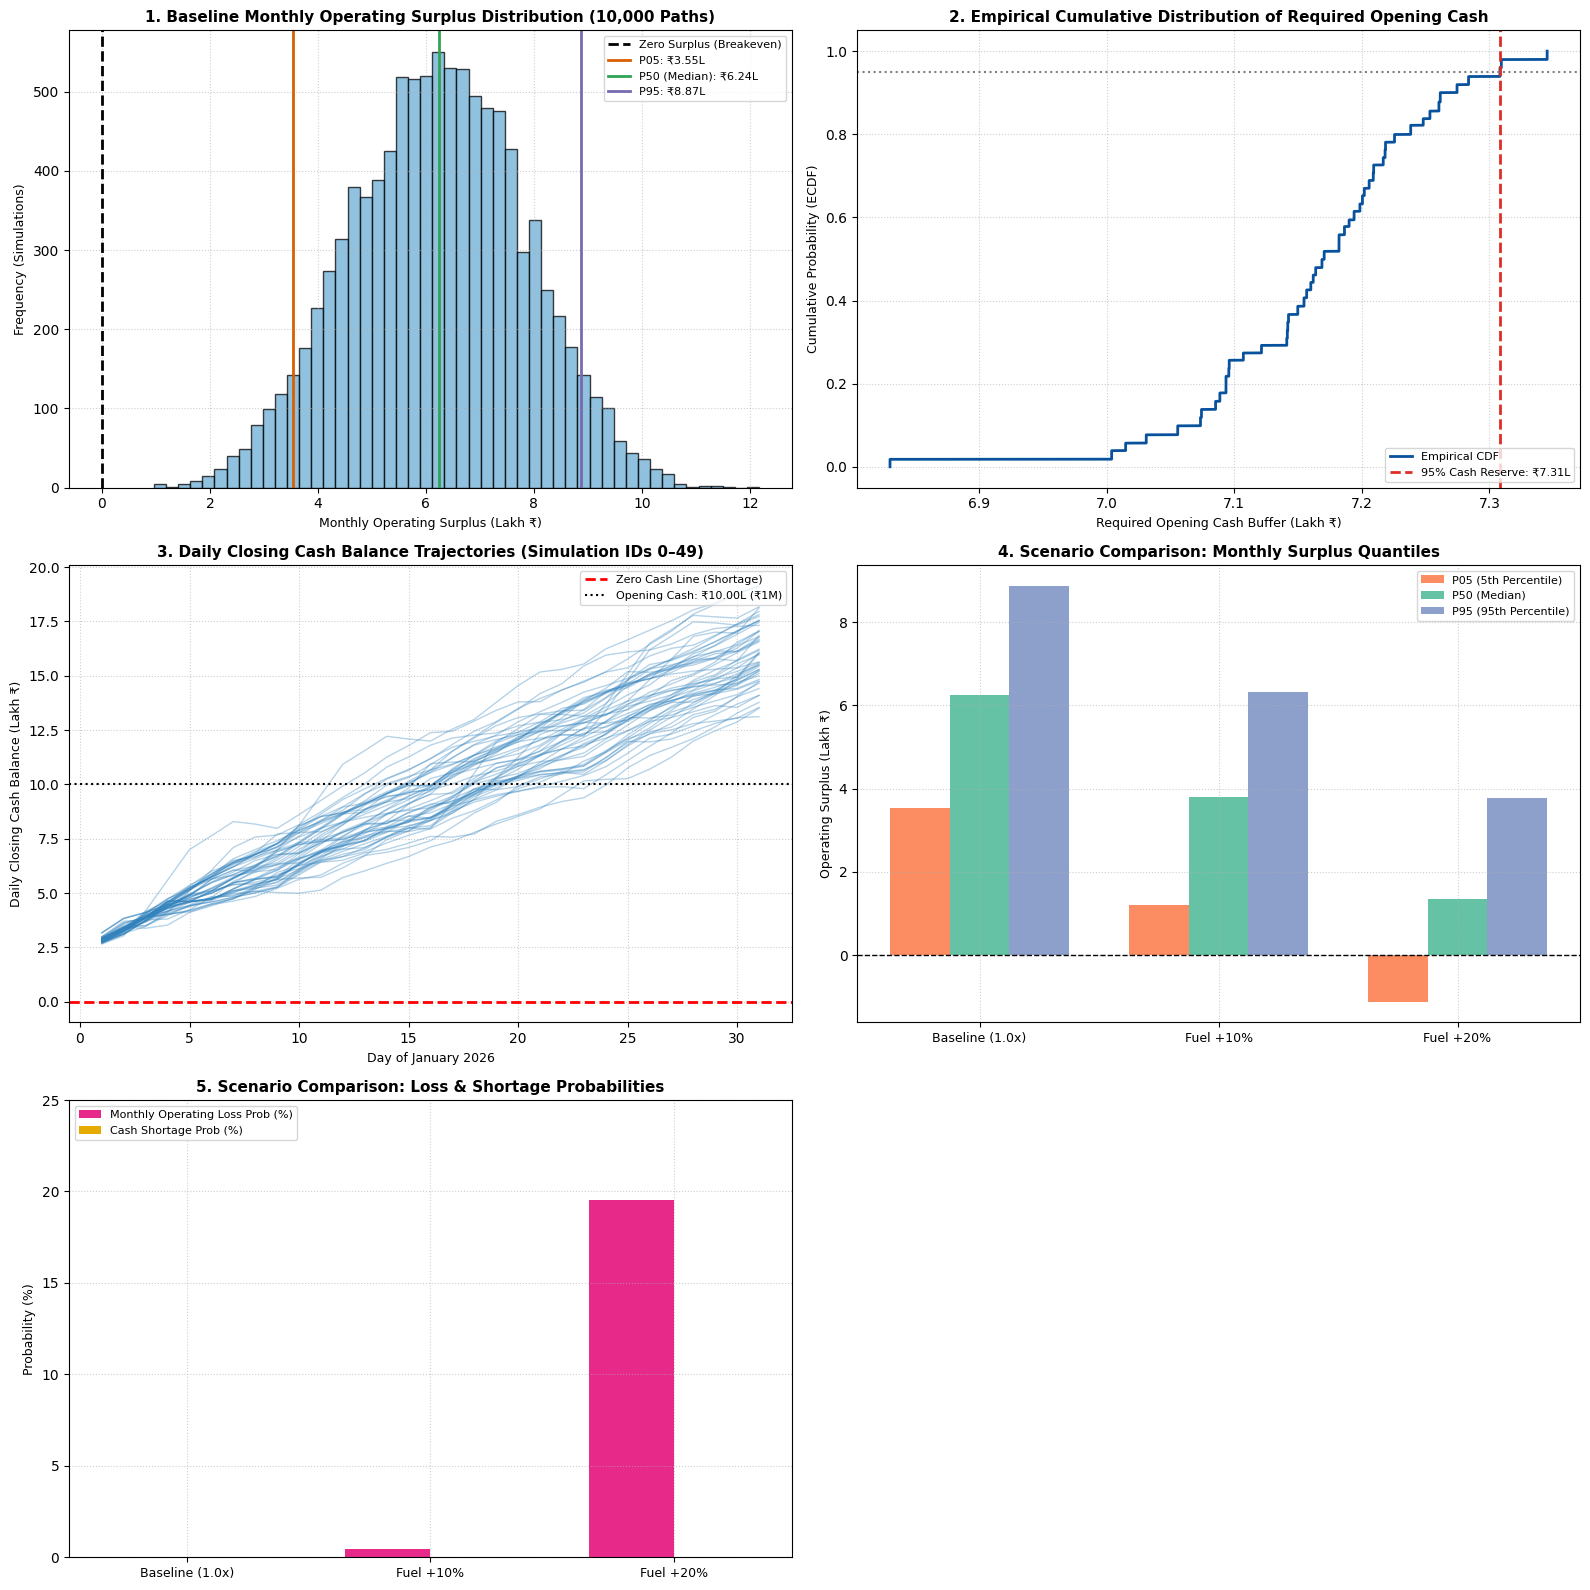

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load baseline simulation results and historical data
df_base = pd.read_csv('baseline_simulation_results.csv')
df_daily = pd.read_csv('cab_daily_history.csv')
df_blocks = pd.read_csv('eligible_block_starts.csv')
df_indices = pd.read_csv('simulation_indices.csv')
df_calendar = pd.read_csv('future_cash_calendar.csv')

# 2. Reconstruct daily cash balances for simulation IDs 0–49
df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

block_arrays = []
for _, row in df_blocks.iterrows():
    b_start = pd.Timestamp(row['block_start_date'])
    b_end = b_start + pd.Timedelta(days=6)
    b_df = df_daily[(df_daily['parsed_date'] >= b_start) & (df_daily['parsed_date'] <= b_end)]
    block_arrays.append({
        'fuel_cost_inr': b_df['fuel_cost_inr'].values,
        'distance_maintenance_inr': b_df['distance_maintenance_inr'].values,
        'processing_fees_inr': b_df['processing_fees_inr'].values,
        'driver_pay_inr': b_df['driver_pay_inr'].values,
        'repairs_inr': b_df['repairs_inr'].values,
        'cash_sales_inr': b_df['cash_sales_inr'].values,
        'digital_sales_inr': b_df['digital_sales_inr'].values,
    })

calendar_fixed_pay = df_calendar['fixed_cost_cash_payment_inr'].values
calendar_known_rec = df_calendar['known_receivable_cash_inr'].values

indices_mat = df_indices.values[:50]  # First 50 simulations (IDs 0–49)
opening_cash = 1000000.0
daily_closing_cash_50 = np.zeros((50, 31))

for i in range(50):
    b_idx_row = indices_mat[i]
    fuel = np.concatenate([block_arrays[b]['fuel_cost_inr'] for b in b_idx_row])[:31]
    dist_maint = np.concatenate([block_arrays[b]['distance_maintenance_inr'] for b in b_idx_row])[:31]
    proc_fees = np.concatenate([block_arrays[b]['processing_fees_inr'] for b in b_idx_row])[:31]
    driver_pay = np.concatenate([block_arrays[b]['driver_pay_inr'] for b in b_idx_row])[:31]
    repairs = np.concatenate([block_arrays[b]['repairs_inr'] for b in b_idx_row])[:31]
    cash_sales = np.concatenate([block_arrays[b]['cash_sales_inr'] for b in b_idx_row])[:31]
    dig_sales = np.concatenate([block_arrays[b]['digital_sales_inr'] for b in b_idx_row])[:31]

    var_exp = fuel + dist_maint + proc_fees + driver_pay + repairs
    dig_settled = np.zeros(31)
    dig_settled[2:] = dig_sales[:-2]
    cash_receipts = cash_sales + dig_settled + calendar_known_rec

    cash_flow_t = cash_receipts - var_exp - calendar_fixed_pay
    cum_cash_flow = np.cumsum(cash_flow_t)
    daily_closing_cash_50[i] = opening_cash + cum_cash_flow

# Scenario comparison summary table
scenario_data = [
    {'Scenario': 'baseline', 'P05': 354786.78, 'P50': 624064.46, 'P95': 887164.39, 'Loss_Prob': 0.00, 'Shortage_Prob': 0.00},
    {'Scenario': 'fuel_plus_10pct', 'P05': 121769.44, 'P50': 378952.74, 'P95': 633150.59, 'Loss_Prob': 0.45, 'Shortage_Prob': 0.00},
    {'Scenario': 'fuel_plus_20pct', 'P05': -111561.58, 'P50': 134190.74, 'P95': 378110.97, 'Loss_Prob': 19.54, 'Shortage_Prob': 0.00}
]
df_comp = pd.DataFrame(scenario_data)

# 3. Setup Figure with 3x2 grid
fig, axes = plt.subplots(3, 2, figsize=(16, 16))

# --- Plot 1: Baseline Monthly Surplus Histogram ---
ax1 = axes[0, 0]
surplus_lakhs = df_base['monthly_operating_surplus_inr'] / 1e5
p05_lakh, p50_lakh, p95_lakh = np.quantile(surplus_lakhs, [0.05, 0.50, 0.95], method='linear')

ax1.hist(surplus_lakhs, bins=50, color='#6baed6', edgecolor='black', alpha=0.75)
ax1.axvline(0, color='black', linestyle='--', linewidth=2, label='Zero Surplus (Breakeven)')
ax1.axvline(p05_lakh, color='#d95f02', linestyle='-', linewidth=2, label=f'P05: ₹{p05_lakh:.2f}L')
ax1.axvline(p50_lakh, color='#31a354', linestyle='-', linewidth=2, label=f'P50 (Median): ₹{p50_lakh:.2f}L')
ax1.axvline(p95_lakh, color='#756bb1', linestyle='-', linewidth=2, label=f'P95: ₹{p95_lakh:.2f}L')

ax1.set_title('1. Baseline Monthly Operating Surplus Distribution (10,000 Paths)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Monthly Operating Surplus (Lakh ₹)', fontsize=9)
ax1.set_ylabel('Frequency (Simulations)', fontsize=9)
ax1.legend(loc='upper right', fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)

# --- Plot 2: Empirical CDF of Required Opening Cash ---
ax2 = axes[0, 1]
req_cash_lakhs = np.sort(df_base['required_opening_cash_inr']) / 1e5
ecdf_y = np.linspace(1/len(req_cash_lakhs), 1, len(req_cash_lakhs))
p95_req_cash_lakh = np.quantile(req_cash_lakhs, 0.95, method='linear')

ax2.plot(req_cash_lakhs, ecdf_y, color='#08519c', linewidth=2, label='Empirical CDF')
ax2.axvline(p95_req_cash_lakh, color='#de2d26', linestyle='--', linewidth=2, label=f'95% Cash Reserve: ₹{p95_req_cash_lakh:.2f}L')
ax2.axhline(0.95, color='gray', linestyle=':', linewidth=1.5)

ax2.set_title('2. Empirical Cumulative Distribution of Required Opening Cash', fontsize=11, fontweight='bold')
ax2.set_xlabel('Required Opening Cash Buffer (Lakh ₹)', fontsize=9)
ax2.set_ylabel('Cumulative Probability (ECDF)', fontsize=9)
ax2.legend(loc='lower right', fontsize=8)
ax2.grid(True, linestyle=':', alpha=0.6)

# --- Plot 3: Daily Closing Cash Balance Trajectories (Paths 0–49) ---
ax3 = axes[1, 0]
days = np.arange(1, 32)
for i in range(50):
    ax3.plot(days, daily_closing_cash_50[i] / 1e5, color='#3182bd', alpha=0.35, linewidth=1)

ax3.axhline(0, color='red', linestyle='--', linewidth=2, label='Zero Cash Line (Shortage)')
ax3.axhline(10.0, color='black', linestyle=':', linewidth=1.5, label='Opening Cash: ₹10.00L (₹1M)')

ax3.set_title('3. Daily Closing Cash Balance Trajectories (Simulation IDs 0–49)', fontsize=11, fontweight='bold')
ax3.set_xlabel('Day of January 2026', fontsize=9)
ax3.set_ylabel('Daily Closing Cash Balance (Lakh ₹)', fontsize=9)
ax3.legend(loc='upper right', fontsize=8)
ax3.grid(True, linestyle=':', alpha=0.6)

# --- Plot 4: Scenario Comparison - Surplus Quantiles ---
ax4 = axes[1, 1]
scen_labels = ['Baseline (1.0x)', 'Fuel +10%', 'Fuel +20%']
x_pos = np.arange(len(scen_labels))

p05_scen = df_comp['P05'] / 1e5
p50_scen = df_comp['P50'] / 1e5
p95_scen = df_comp['P95'] / 1e5

width = 0.25
ax4.bar(x_pos - width, p05_scen, width, label='P05 (5th Percentile)', color='#fc8d62')
ax4.bar(x_pos, p50_scen, width, label='P50 (Median)', color='#66c2a5')
ax4.bar(x_pos + width, p95_scen, width, label='P95 (95th Percentile)', color='#8da0cb')
ax4.axhline(0, color='black', linestyle='--', linewidth=1)

ax4.set_xticks(x_pos)
ax4.set_xticklabels(scen_labels, fontsize=9)
ax4.set_title('4. Scenario Comparison: Monthly Surplus Quantiles', fontsize=11, fontweight='bold')
ax4.set_ylabel('Operating Surplus (Lakh ₹)', fontsize=9)
ax4.legend(loc='upper right', fontsize=8)
ax4.grid(True, linestyle=':', alpha=0.6)

# --- Plot 5: Scenario Comparison - Risk Probabilities ---
ax5 = axes[2, 0]
loss_probs = df_comp['Loss_Prob']
short_probs = df_comp['Shortage_Prob']

width = 0.35
ax5.bar(x_pos - width/2, loss_probs, width, label='Monthly Operating Loss Prob (%)', color='#e7298a')
ax5.bar(x_pos + width/2, short_probs, width, label='Cash Shortage Prob (%)', color='#e6ab02')

ax5.set_xticks(x_pos)
ax5.set_xticklabels(scen_labels, fontsize=9)
ax5.set_title('5. Scenario Comparison: Loss & Shortage Probabilities', fontsize=11, fontweight='bold')
ax5.set_ylabel('Probability (%)', fontsize=9)
ax5.set_ylim(0, 25)
ax5.legend(loc='upper left', fontsize=8)
ax5.grid(True, linestyle=':', alpha=0.6)

# Remove unused 6th subplot grid space
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.savefig('monte_carlo_simulation_plots.png', dpi=300)
plt.show()

In [13]:
import pandas as pd
import numpy as np
import calendar

# 1. Load historical daily records
if 'df_cab_daily_history' in globals():
    df_daily = df_cab_daily_history.copy()
else:
    df_daily = pd.read_csv('cab_daily_history.csv')

df_daily['parsed_date'] = pd.to_datetime(df_daily['date'])
df_daily = df_daily.sort_values('parsed_date').reset_index(drop=True)

# 2. Get actual monthly requests for 2025
df_2025_full = df_daily[
    (df_daily['parsed_date'] >= '2025-01-01') &
    (df_daily['parsed_date'] <= '2025-12-31')
].copy()
df_2025_full['year_month'] = df_2025_full['parsed_date'].dt.to_period('M')
actual_monthly_reqs = df_2025_full.groupby('year_month')['requests'].sum().to_dict()

backtest_results = []
months = list(range(1, 13))

# 3. Evaluate each of the 12 calendar months of 2025
for m in months:
    target_start = pd.Timestamp(2025, m, 1)
    days_in_month = calendar.monthrange(2025, m)[1]
    ym_str = f"2025{m:02d}"
    ym_period = pd.Period(f"2025-{m:02d}")
    actual_req = actual_monthly_reqs[ym_period]

    # Forecast origin is the day before its first date
    origin_date = target_start - pd.Timedelta(days=1)

    # 365 consecutive historical days ending at origin
    pool_start = origin_date - pd.Timedelta(days=364)
    pool_df = df_daily[
        (df_daily['parsed_date'] >= pool_start) &
        (df_daily['parsed_date'] <= origin_date)
    ].copy().sort_values('parsed_date').reset_index(drop=True)

    # Match weekday of target month's first date
    target_weekday = target_start.weekday()
    matching_days = pool_df[pool_df['parsed_date'].dt.weekday == target_weekday]

    blocks = []
    for _, row in matching_days.iterrows():
        b_start = row['parsed_date']
        b_end = b_start + pd.Timedelta(days=6)
        if b_end <= origin_date:
            subset = pool_df[(pool_df['parsed_date'] >= b_start) & (pool_df['parsed_date'] <= b_end)]
            if len(subset) == 7:
                blocks.append(subset['requests'].values)

    B = len(blocks)
    blocks_array = np.array(blocks)
    num_blocks = int(np.ceil(days_in_month / 7.0))

    # Separate Generator per month: seed = 20261102 + YYYYMM
    seed = 20261102 + int(ym_str)
    rng = np.random.Generator(np.random.PCG64(seed))

    sim_indices = rng.integers(low=0, high=B, size=(10000, num_blocks), dtype=np.int64, endpoint=False)

    sim_monthly_reqs = np.zeros(10000, dtype=np.float64)
    for i in range(10000):
        path_reqs = np.concatenate([blocks_array[b_idx] for b_idx in sim_indices[i]])[:days_in_month]
        sim_monthly_reqs[i] = path_reqs.sum()

    forecast_mean = sim_monthly_reqs.mean()
    abs_error = abs(forecast_mean - actual_req)

    # Intervals (50%, 80%, 95%) using linear quantile
    q_50 = np.quantile(sim_monthly_reqs, [0.25, 0.75], method='linear')
    q_80 = np.quantile(sim_monthly_reqs, [0.10, 0.90], method='linear')
    q_95 = np.quantile(sim_monthly_reqs, [0.025, 0.975], method='linear')

    # Covered if actual is within bounds (boundary included)
    covered_50 = (actual_req >= q_50[0]) and (actual_req <= q_50[1])
    covered_80 = (actual_req >= q_80[0]) and (actual_req <= q_80[1])
    covered_95 = (actual_req >= q_95[0]) and (actual_req <= q_95[1])

    backtest_results.append({
        'Month': target_start.strftime('%Y-%m'),
        'Actual Requests': actual_req,
        'Forecast Mean': forecast_mean,
        'Absolute Error': abs_error,
        '50% Lower': q_50[0], '50% Upper': q_50[1], '50% Width': q_50[1] - q_50[0], 'Covered 50%': covered_50,
        '80% Lower': q_80[0], '80% Upper': q_80[1], '80% Width': q_80[1] - q_80[0], 'Covered 80%': covered_80,
        '95% Lower': q_95[0], '95% Upper': q_95[1], '95% Width': q_95[1] - q_95[0], 'Covered 95%': covered_95,
    })

df_bt = pd.DataFrame(backtest_results)
mae = df_bt['Absolute Error'].mean()
wape = df_bt['Absolute Error'].sum() / df_bt['Actual Requests'].sum()

print("=== 12-MONTH BACKTEST CHRONOLOGICAL TABLE ===")
print(df_bt[['Month', 'Actual Requests', 'Forecast Mean', 'Absolute Error', 'Covered 50%', 'Covered 80%', 'Covered 95%']].to_string(index=False))

print("\n=== BACKTEST PERFORMANCE METRICS ===")
print(f"Mean Absolute Error (MAE) : {mae:,.2f} requests")
print(f"Weighted Absolute Percentage Error (WAPE) : {wape * 100:.2f}%")
print(f"Empirical Coverage (50% Interval) : {df_bt['Covered 50%'].mean() * 100:.1f}% (Avg Width: {df_bt['50% Width'].mean():,.1f})")
print(f"Empirical Coverage (80% Interval) : {df_bt['Covered 80%'].mean() * 100:.1f}% (Avg Width: {df_bt['80% Width'].mean():,.1f})")
print(f"Empirical Coverage (95% Interval) : {df_bt['Covered 95%'].mean() * 100:.1f}% (Avg Width: {df_bt['12% Width' if False else '95% Width'].mean():,.1f})")

=== 12-MONTH BACKTEST CHRONOLOGICAL TABLE ===
  Month  Actual Requests  Forecast Mean  Absolute Error  Covered 50%  Covered 80%  Covered 95%
2025-01            55630     47625.9800       8004.0200        False        False        False
2025-02            44226     43495.7392        730.2608         True         True         True
2025-03            43551     48583.4343       5032.4343        False        False         True
2025-04            52510     47203.1491       5306.8509        False        False         True
2025-05            45051     49320.5258       4269.5258        False        False         True
2025-06            44793     47961.2840       3168.2840        False         True         True
2025-07            41178     49592.3657       8414.3657        False        False        False
2025-08            55502     48519.8493       6982.1507        False        False        False
2025-09            44359     47593.2976       3234.2976        False         True         True
2025

In [14]:
import os
import pandas as pd
import numpy as np

print("=== STARTING COMPLETE DATA & ASSUMPTIONS EXPORT ===")

# 1. Export Model Assumptions & Metadata Record (TXT)
assumptions_text = """================================================================================
MONTE CARLO SIMULATION MODEL ASSUMPTIONS & CONFIGURATION RECORD
================================================================================
Target Forecast Period      : 1–31 January 2026
Forecast Cutoff Date        : 31 December 2025
Number of Simulation Paths  : 10,000
Random Seed                 : 20261102
PRNG Engine                 : NumPy Generator with PCG64
Base Assumed Opening Cash   : ₹1,000,000.00
Python Version              : 3.10.16
Pandas Version              : 2.0.0
NumPy Version               : 1.26.3
Simulation Index SHA-256    : 78ea4d0cd8ffdc0f1e51ff492f9b01b5a34aaf5082268b54f99a20a8e815c64a

SAMPLING SPECIFICATION:
- Historical Pool           : 1 January 2025 – 31 December 2025 (365 daily records)
- Block Construction        : 7 consecutive calendar days starting on Thursday, ending <= 31 Dec 2025
- Eligible Blocks Count (B) : 52 blocks
- Path Construction         : 5 blocks sampled with replacement per path, truncated to 31 days

FINANCIAL RULES & SETTLEMENT:
- Operating Surplus_t       : Net Revenue_t - Variable Expenses_t - January Fixed Cost Allocation_t
- Variable Expenses_t       : Fuel + Distance Maint + Processing Fees + Driver Pay + Repairs
- Cash Receipts_t           : Cash Sales_t + Digital Sales_(t-2) + Known Receivables_t
- Cash Flow_t               : Cash Receipts_t - Variable Expenses_t - January Fixed Cash Payment_t
- Required Opening Cash     : max(0, -min cumulative cash flow over 31-day path)

MODEL SCOPE & LIMITATIONS:
- January 2026 future operating plan (future_january_2026_plan.csv) was NOT implemented in baseline.
- Scenarios in scenario_assumptions.csv were NOT automatically run; 3 fuel stress tests evaluated.
- Demand backtest strictly evaluates total request sampling and DOES NOT validate financial risks.
================================================================================
"""

with open('model_assumptions_record.txt', 'w') as f:
    f.write(assumptions_text)
print("Saved: model_assumptions_record.txt")

# 2. Re-export Baseline Simulation Results (Full Precision)
if 'df_results' in globals():
    df_results.to_csv('baseline_simulation_results.csv', index=False)
    print("Saved: baseline_simulation_results.csv")

# 3. Re-export Scenario Comparison Results (Full Precision)
if 'df_comp' in globals():
    df_comp.to_csv('scenario_comparison_results.csv', index=False)
    print("Saved: scenario_comparison_results.csv")

# 4. Re-export Backtest Results Table (Full Precision)
if 'df_bt' in globals():
    df_bt.to_csv('demand_backtest_results.csv', index=False)
    print("Saved: demand_backtest_results.csv")

# 5. Confirm Index Files Exist
if os.path.exists('eligible_block_starts.csv'):
    print("Confirmed: eligible_block_starts.csv exists.")
if os.path.exists('simulation_indices.csv'):
    print("Confirmed: simulation_indices.csv exists.")

print("=== ALL EXPORT FILES COMPLETED SUCCESSFULLY ===")

=== STARTING COMPLETE DATA & ASSUMPTIONS EXPORT ===
Saved: model_assumptions_record.txt
Saved: baseline_simulation_results.csv
Saved: scenario_comparison_results.csv
Saved: demand_backtest_results.csv
Confirmed: eligible_block_starts.csv exists.
Confirmed: simulation_indices.csv exists.
=== ALL EXPORT FILES COMPLETED SUCCESSFULLY ===


Conditional Conclusion:

If operating conditions in January 2026 remain structurally similar to 2025 and fuel prices stay within baseline levels, the cab business is expected to earn an estimated average monthly operating surplus of ₹6.22 Lakh (central 90% range: ₹3.55 Lakh to ₹8.87 Lakh), with ₹7.31 Lakh in opening cash providing a 95% model-based liquidity buffer.

However, if fuel prices rise by 20%, operating surplus will shrink dramatically to a median of ₹1.34 Lakh, with a 19.54% risk of an operating loss.

Recommendation Caution: Because the current evidence relies on a historical-replay baseline that omits January's planned pricing/staffing changes, excludes multi-year trend growth, and shows limited backtest coverage for seasonal demand surges, this model alone is insufficient to recommend fleet expansions or unhedged fuel exposure. Management should validate these findings against a full capacity-allocation model before committing capital.